# Final EDA Notebook

$\textit{by Anmol Anand (MS24063)}$

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
df1 = pd.read_csv('student-mat.csv', sep=';')
df2 = pd.read_csv('student-por.csv', sep=';')
# df.head()

## Grade Distribution

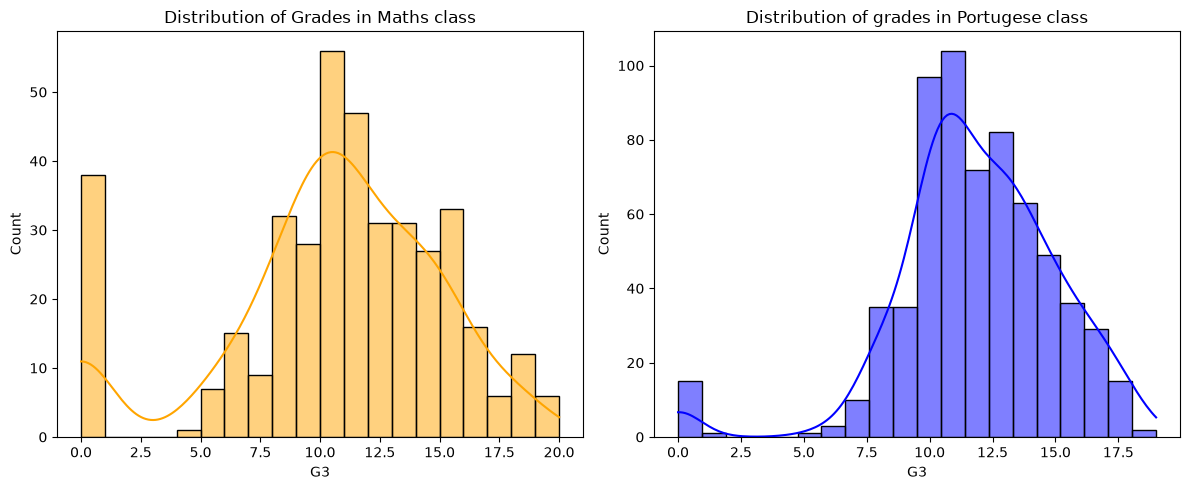

In [18]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

sns.histplot(data=df1, x="G3", kde=True, ax=axes[0], color="orange", bins=20)
axes[0].set_title("Distribution of Grades in Maths class")
sns.histplot(data=df2, x="G3", kde=True, ax=axes[1], color="blue", bins = 20)
axes[1].set_title("Distribution of grades in Portugese class")

plt.tight_layout()
plt.show()

## Correlation Heatmaps

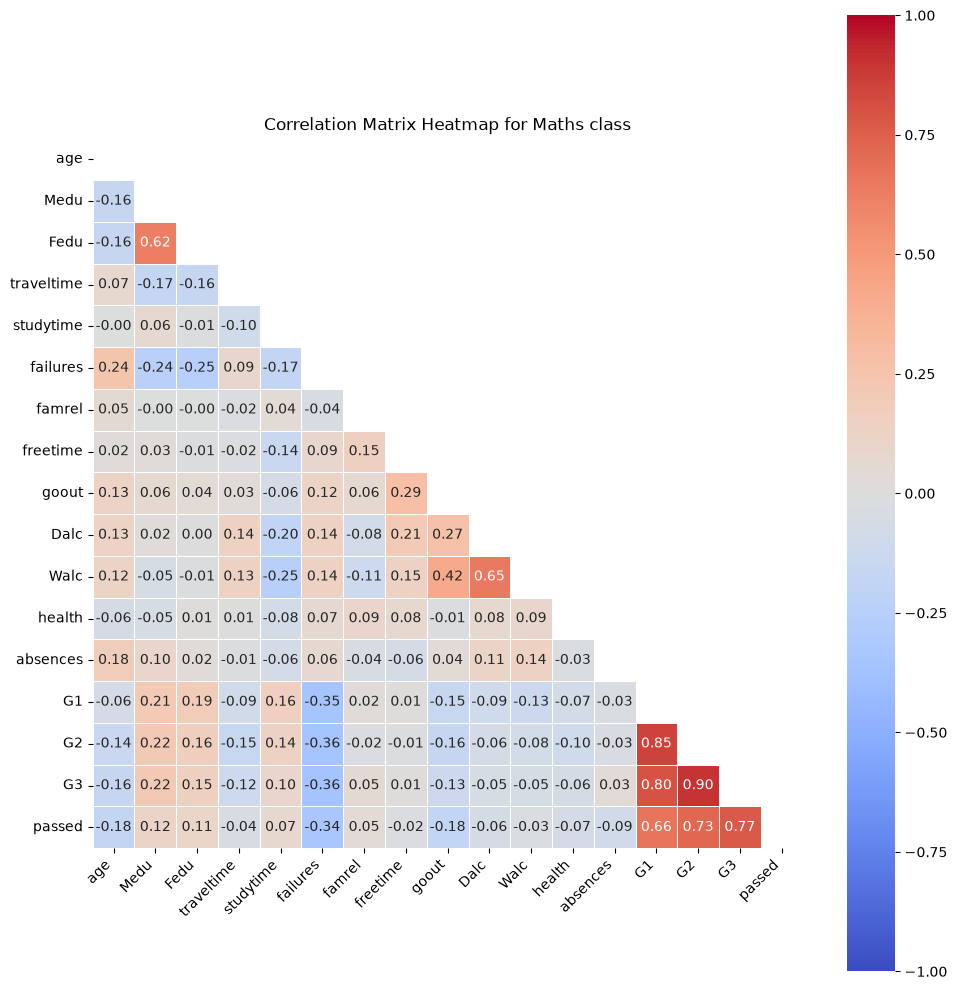

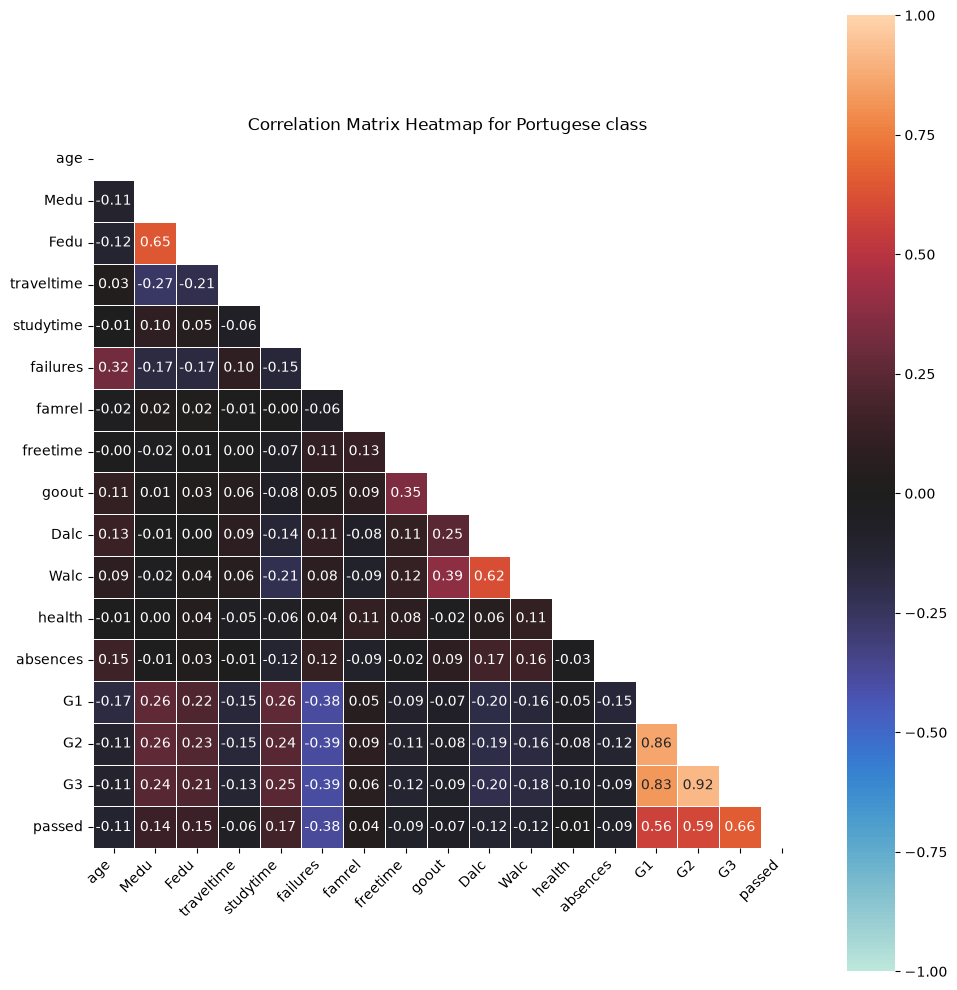

In [134]:
plt.figure(figsize=(10, 10))
corr_matrix = df1.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",  # Good divergent color palette for negative (-1) to positive (+1) rules
    vmin=-1,
    vmax=1,  # Forces the color boundaries to represent true correlation limits
    center=0,  # Centers the neutral color at 0 (no correlation)
    square=True,  # Forces the grid cells to be perfectly square
    linewidths=0.5,  # Adds clean dividers between squares
)
plt.title("Correlation Matrix Heatmap for Maths class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 10))
corr_matrix = df2.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    # cmap="coolwarm",  # Good divergent color palette for negative (-1) to positive (+1) rules
    vmin=-1,
    vmax=1,  # Forces the color boundaries to represent true correlation limits
    center=0,  # Centers the neutral color at 0 (no correlation)
    square=True,  # Forces the grid cells to be perfectly square
    linewidths=0.5,  # Adds clean dividers between squares
)
plt.title("Correlation Matrix Heatmap for Portugese class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

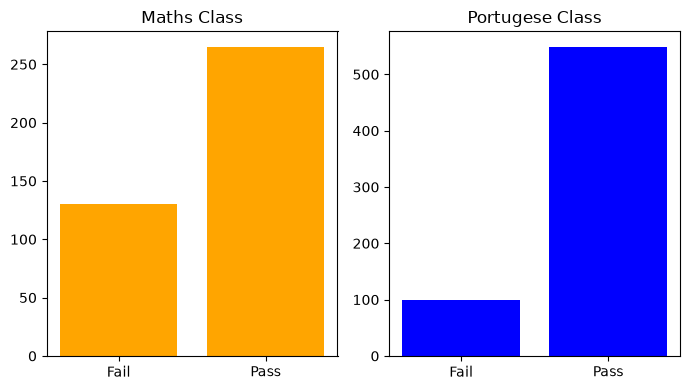

In [81]:
grades1 = df1['G3'].to_numpy()
grades2 = df2['G3'].to_numpy()

pf1 = np.ones(len(grades1))
pf2 = np.ones(len(grades2))

for i in range(len(grades1)):
    if grades1[i]<10:
        pf1[i] = 0
for i in range(len(grades2)):
    if grades2[i]<10:
        pf2[i] = 0

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7, 4))
axes[0].bar(['Fail', 'Pass'], [len(pf1[pf1==0]), len(pf1[pf1==1])], color='orange')
axes[0].set_title('Maths Class')
axes[1].bar(['Fail', 'Pass'], [len(pf2[pf2==0]), len(pf2[pf2==1])], color='blue')
axes[1].set_title('Portugese Class')

plt.tight_layout()
plt.show()

## Study Time vs Final Grades

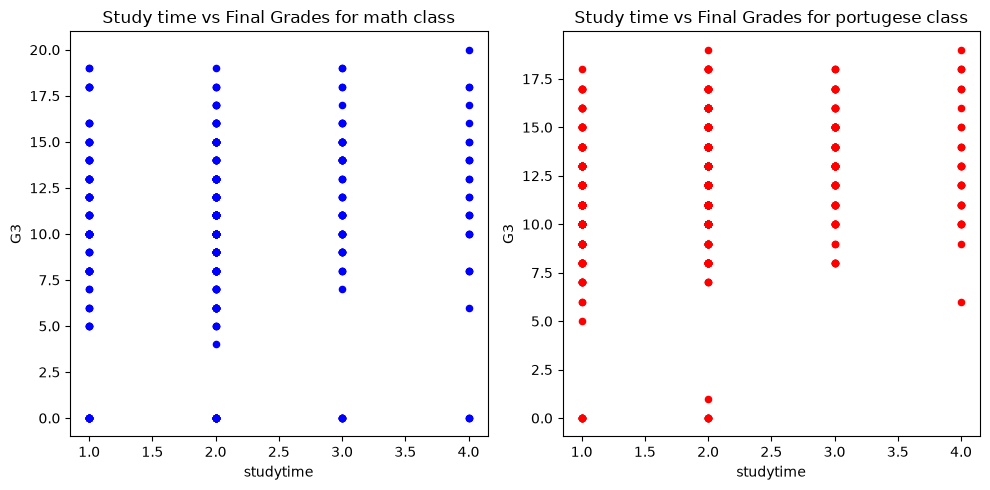

In [88]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
df1.plot(kind='scatter', x='studytime', y='G3', color='blue', ax=axes[0])
axes[0].set_title("Study time vs Final Grades for math class")

df2.plot(kind='scatter', x='studytime', y='G3', color='red', ax=axes[1])
axes[1].set_title("Study time vs Final Grades for portugese class")

plt.tight_layout()
plt.show()

## Absences vs Final Grades

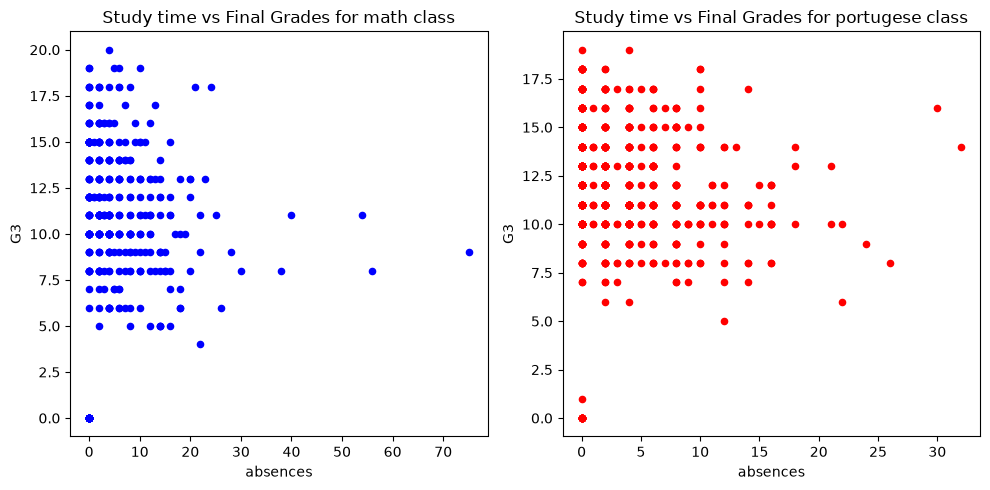

In [43]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
df1.plot(kind='scatter', x='absences', y='G3', color='blue', ax=axes[0])
axes[0].set_title("Study time vs Final Grades for math class")

df2.plot(kind='scatter', x='absences', y='G3', color='red', ax=axes[1])
axes[1].set_title("Study time vs Final Grades for portugese class")

plt.tight_layout()
plt.show()

## Alcohol Consumption vs Final Grades

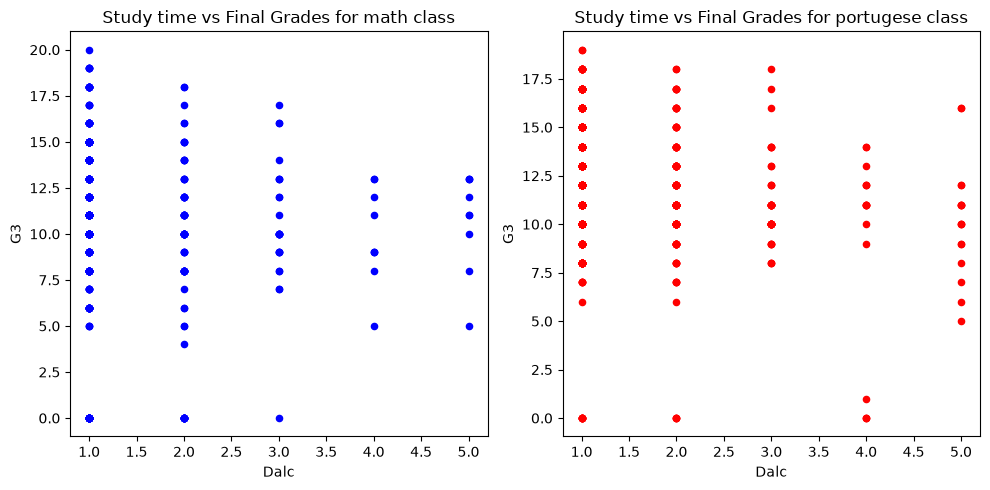

(395, 33)

In [87]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
df1.plot(kind='scatter', x='Dalc', y='G3', color='blue', ax=axes[0])
axes[0].set_title("Study time vs Final Grades for math class")

df2.plot(kind='scatter', x='Dalc', y='G3', color='red', ax=axes[1])
axes[1].set_title("Study time vs Final Grades for portugese class")

plt.tight_layout()
plt.show()

df1.shape

## Pass Rate vs Study Time

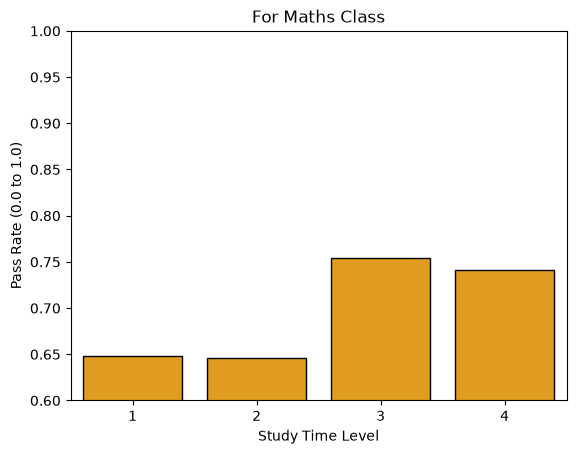

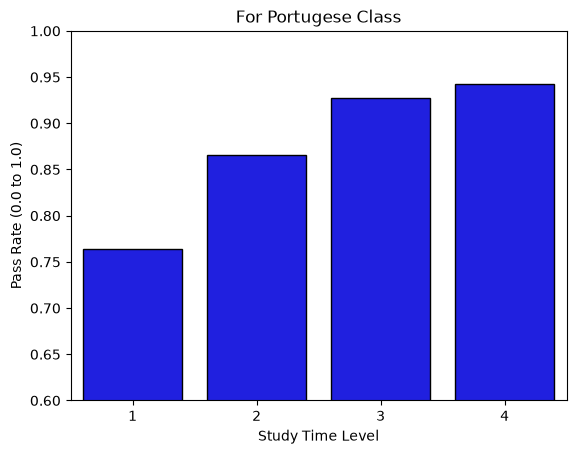

In [119]:
df1['passed'] = pf1

# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='studytime', y='passed', data=df1, errorbar=None, color='orange', edgecolor='black')

# 3. Add labels and show
plt.title('For Maths Class')
plt.xlabel('Study Time Level')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

df2['passed'] = pf2

# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='studytime', y='passed', data=df2, errorbar=None, color='blue', edgecolor='black')

# 3. Add labels and show
plt.title('For Portugese Class')
plt.xlabel('Study Time Level')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

## Pass Rate vs Alcohol Consumption

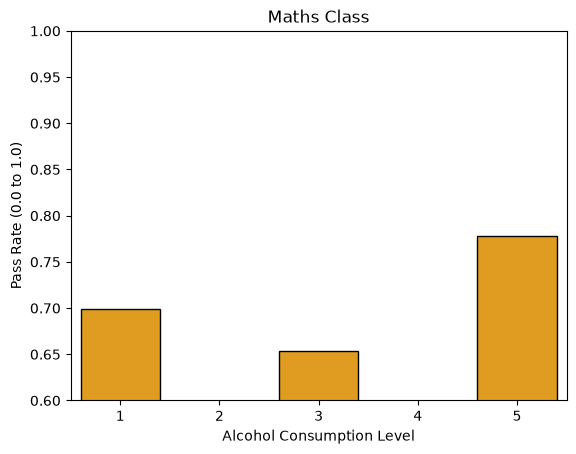

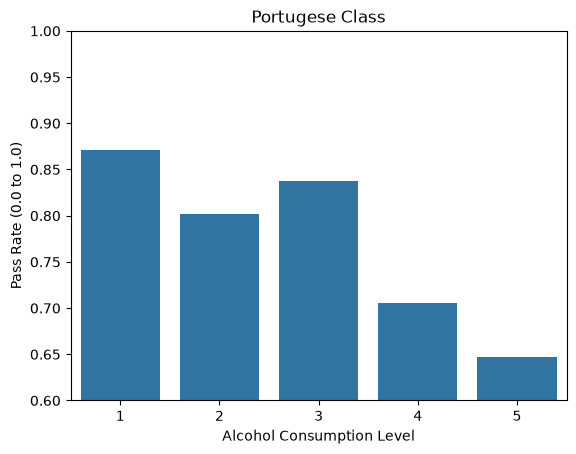

In [121]:
# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='Dalc', y='passed', data=df1, errorbar=None,  color='orange', edgecolor='black')

# 3. Add labels and show
plt.title('Maths Class')
plt.xlabel('Alcohol Consumption Level')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='Dalc', y='passed', data=df2, errorbar=None)

# 3. Add labels and show
plt.title('Portugese Class')
plt.xlabel('Alcohol Consumption Level')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

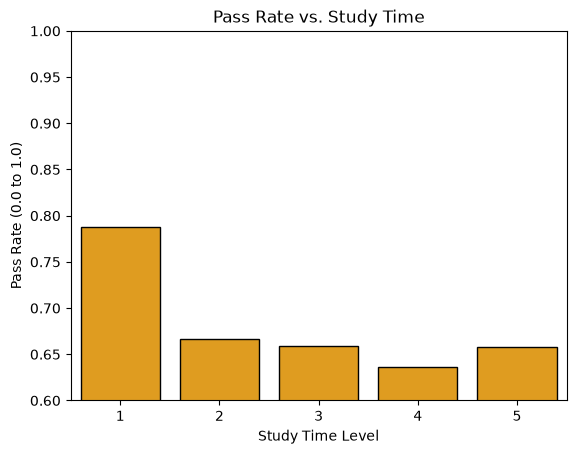

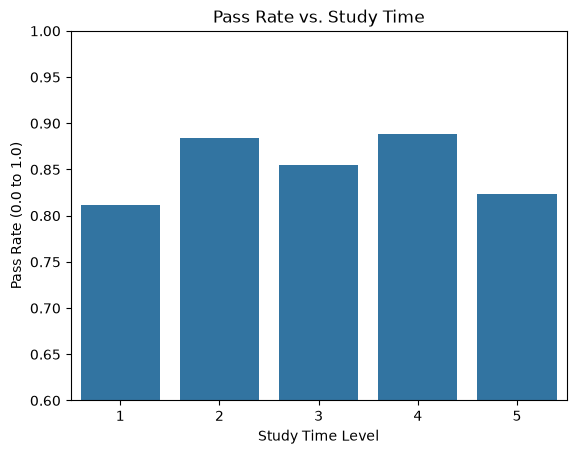

In [122]:
df1['passed'] = pf1

# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='health', y='passed', data=df1, errorbar=None, color='orange', edgecolor='black')

# 3. Add labels and show
plt.title('Pass Rate vs. Study Time')
plt.xlabel('Study Time Level')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

df2['passed'] = pf2

# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='health', y='passed', data=df2, errorbar=None)

# 3. Add labels and show
plt.title('Pass Rate vs. Study Time')
plt.xlabel('Study Time Level')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

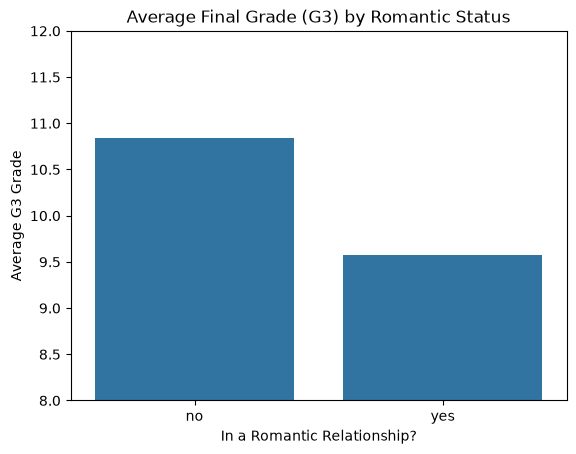

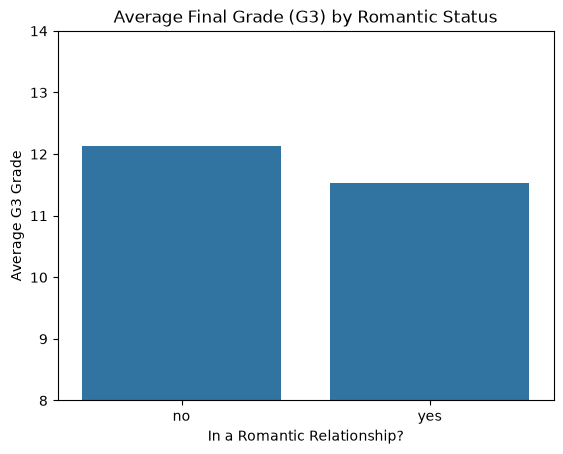

In [113]:


sns.barplot(x='romantic', y='G3', data=df1, errorbar=None)

plt.title('Average Final Grade (G3) by Romantic Status')
plt.xlabel('In a Romantic Relationship?')
plt.ylabel('Average G3 Grade')
plt.ylim(8, 12)
plt.show()

sns.barplot(x='romantic', y='G3', data=df2, errorbar=None)

plt.title('Average Final Grade (G3) by Romantic Status')
plt.xlabel('In a Romantic Relationship?')
plt.ylabel('Average G3 Grade')
plt.ylim(8, 14)
plt.show()

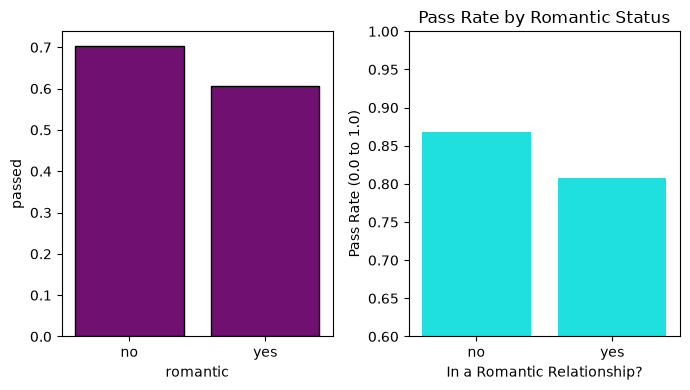

In [129]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7, 4))

sns.barplot(x='romantic', y='passed', data=df1, errorbar=None, color='purple', edgecolor='black', ax=axes[0])
# 3. Customize the chart
plt.title('Pass Rate by Romantic Status')
plt.xlabel('In a Romantic Relationship?')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.5, 0.8) # Force Y-axis to go from 0% to 100%


sns.barplot(x='romantic', y='passed', data=df2, errorbar=None, color= 'cyan', ax=axes[1])

# 3. Customize the chart
plt.title('Pass Rate by Romantic Status')
plt.xlabel('In a Romantic Relationship?')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1) # Force Y-axis to go from 0% to 100%

plt.tight_layout()
plt.show()

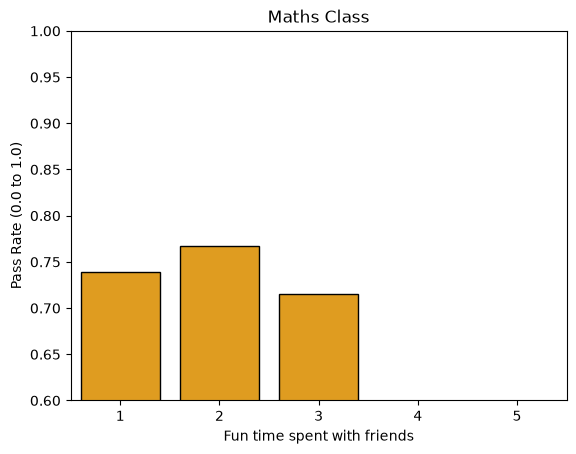

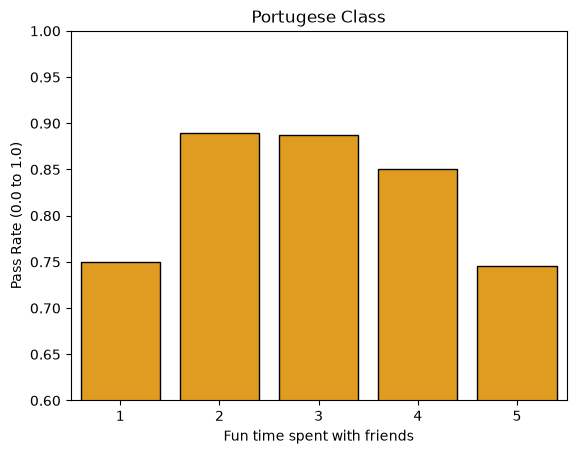

In [133]:
# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='goout', y='passed', data=df1, errorbar=None,  color='orange', edgecolor='black')

# 3. Add labels and show
plt.title('Maths Class')
plt.xlabel('Fun time spent with friends')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

# 2. Plot using Seaborn's barplot (it calculates the mean/rate automatically)
sns.barplot(x='goout', y='passed', data=df2, errorbar=None, color='orange', edgecolor='black')

# 3. Add labels and show
plt.title('Portugese Class')
plt.xlabel('Fun time spent with friends')
plt.ylabel('Pass Rate (0.0 to 1.0)')
plt.ylim(0.6, 1)
plt.show()

([0, 1, 2, 3],
 [Text(0, 0, 'Lin Reg'),
  Text(1, 0, 'Rnd Forest'),
  Text(2, 0, 'Decision Tree'),
  Text(3, 0, 'Baseline')])

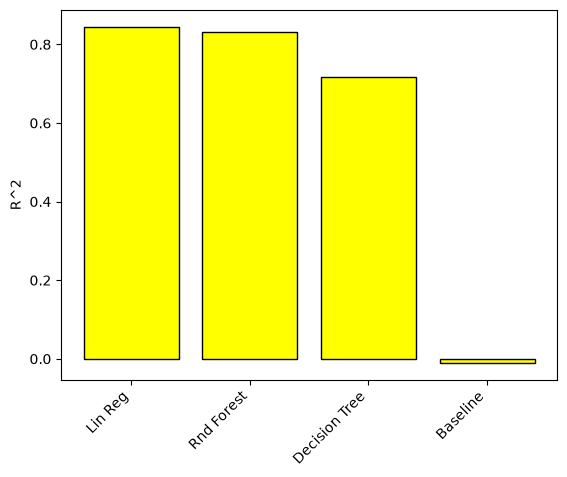

In [149]:
plt.bar(['Lin Reg', 'Rnd Forest', 'Decision Tree', 'Baseline'],[0.845, 0.832, 0.717, -0.01], color='yellow', edgecolor='black')
plt.figsize=(7, 4)
plt.ylabel('R^2')

plt.xticks(rotation=45, ha="right")

([0, 1, 2, 3],
 [Text(0, 0, 'Lin Reg'),
  Text(1, 0, 'Rnd Forest'),
  Text(2, 0, 'Decision Tree'),
  Text(3, 0, 'Baseline')])

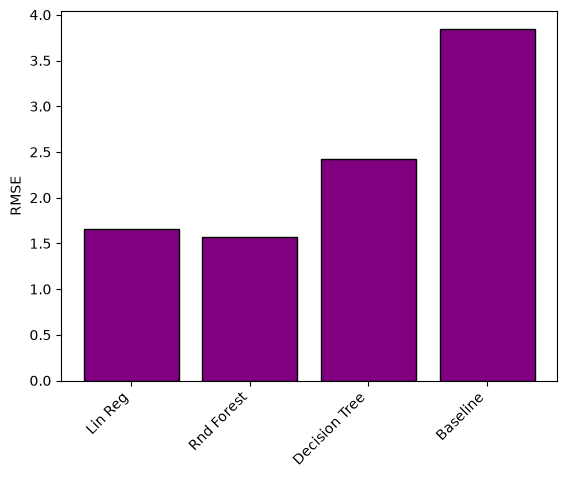

In [153]:
plt.bar(['Lin Reg', 'Rnd Forest', 'Decision Tree', 'Baseline'],[1.66, 1.57, 2.42, 3.85], color='purple', edgecolor='black')
plt.figsize=(7, 4)
plt.ylabel('RMSE')

plt.xticks(rotation=45, ha="right")